# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [3]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)
    
    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))            
        
            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")
            
            print("Please enter a valid move.")
            

    return(move)

## Start an interactive game as x

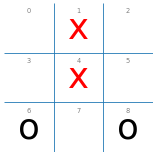

Available actions are: [0, 2, 3, 5, 7]


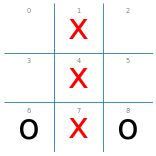

{'x': 1, 'o': 0, 'd': 0}

In [8]:
play(interactive_player, random_player, N = 1,  show_final_board=True)

### Start an interactive game as o

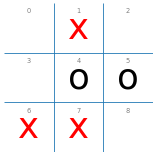

Available actions are: [0, 2, 3, 8]


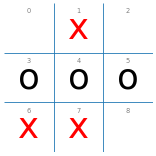

{'x': 0, 'o': 1, 'd': 0}

In [7]:
play(random_player, interactive_player, N = 1, show_final_board = True)

### Ghi nhận Ván đấu Mô phỏng Tương tác với Tác tử Alpha-Beta (Bài 7 - Lab 05)
Bên cạnh hàm `interactive_player()` tương tác trực tiếp bằng bàn phím, đoạn mã dưới đây cài đặt tác tử `alpha_beta_player` (với move ordering) và ghi lại đầy đủ diễn biến 2 ván đấu đối kháng ở cả hai vai **X (đi trước)** và **O (đi sau)**.

=== Alpha-Beta Agent (X) vs Người chơi (mô phỏng) (O) ===
Bước 1 (X - Alpha-Beta Agent) -> chọn ô 4 | Bàn cờ: [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' ']
Bước 2 (O - Người chơi (mô phỏng)) -> chọn ô 7 | Bàn cờ: [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' ']
Bước 3 (X - Alpha-Beta Agent) -> chọn ô 8 | Bàn cờ: [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', 'x']
Bước 4 (O - Người chơi (mô phỏng)) -> chọn ô 3 | Bàn cờ: [' ', ' ', ' ', 'o', 'x', ' ', ' ', 'o', 'x']
Bước 5 (X - Alpha-Beta Agent) -> chọn ô 6 | Bàn cờ: [' ', ' ', ' ', 'o', 'x', ' ', 'x', 'o', 'x']
Bước 6 (O - Người chơi (mô phỏng)) -> chọn ô 0 | Bàn cờ: ['o', ' ', ' ', 'o', 'x', ' ', 'x', 'o', 'x']
Bước 7 (X - Alpha-Beta Agent) -> chọn ô 2 | Bàn cờ: ['o', ' ', 'x', 'o', 'x', ' ', 'x', 'o', 'x']
--> Kết thúc: X!
=== Người chơi (mô phỏng) (X) vs Alpha-Beta Agent (O) ===
Bước 1 (X - Người chơi (mô phỏng)) -> chọn ô 7 | Bàn cờ: [' ', ' ', ' ', ' ', ' ', ' ', ' ', 'x', ' ']
Bước 2 (O - Alpha-Beta Agent) -> chọn ô 4 | Bàn cờ: [' ', ' ', 

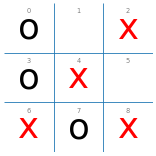

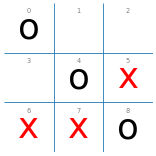

In [4]:
import math, numpy as np
from tictactoe import check_board

def ordered_actions(board):
    acts = np.where(np.array(board) == ' ')[0].tolist()
    prio = [1,0,1, 0,2,0, 1,0,1]
    return [a for _, a in sorted(zip([prio[i] for i in acts], acts), reverse=True)]

def ab_player(board, player='x'):
    def max_v(s, p, a, b):
        u = utility(s, p)
        if u is not None: return u, None
        v, m = -math.inf, None
        for act in ordered_actions(s):
            v2, _ = min_v(result(s, p, act), p, a, b)
            if v2 > v: v, m = v2, act; a = max(a, v)
            if v >= b: return v, m
        return v, m
    def min_v(s, p, a, b):
        u = utility(s, p)
        if u is not None: return u, None
        v, m = +math.inf, None
        for act in ordered_actions(s):
            v2, _ = max_v(result(s, other(p), act), p, a, b)
            if v2 < v: v, m = v2, act; b = min(b, v)
            if v <= a: return v, m
        return v, m
    _, mv = max_v(board, player, -math.inf, +math.inf)
    return mv

def run_trace_match(px, po, label_x, label_o):
    b = empty_board(); step = 1; turn = 'x'
    print(f'=== {label_x} (X) vs {label_o} (O) ===')
    while True:
        mv = px(b, 'x') if turn == 'x' else po(b, 'o')
        b = result(b, turn, mv)
        who = label_x if turn == 'x' else label_o
        print(f'Bước {step} ({turn.upper()} - {who}) -> chọn ô {mv} | Bàn cờ: {b}')
        st = check_board(b)
        if st != 'n':
            print(f'--> Kết thúc: {st.upper() if st != "d" else "HÒA"}!')
            show_board(b)
            break
        turn = other(turn); step += 1

np.random.seed(42)
run_trace_match(ab_player, random_player, 'Alpha-Beta Agent', 'Người chơi (mô phỏng)')
run_trace_match(random_player, ab_player, 'Người chơi (mô phỏng)', 'Alpha-Beta Agent')


**Nhận xét chiến lược của tác tử:**
- **Khi cầm X (đi trước):** Tác tử lập tức chiếm ô trung tâm `4`, sau đó phối hợp với các ô góc `8` và `6` để tạo bẫy đôi (double threat trên 2 đường chéo `0-4-8` và `2-4-6`), khiến đối thủ không thể đỡ cả hai cùng lúc và thắng gọn ở bước 7 tại ô `2`.
- **Khi cầm O (đi sau):** Tác tử chiếm ngay ô trung tâm `4` nếu còn trống, chủ động chặn đứng hàng 2 quân của X (ô `2`), rồi phản công thắng ở bước 6 tại ô `6`.